# 06 · LightGBM, calibration and risk bands

**FinGuard AI, Phase 2.** Reads `artifacts/phase2/` (run `python -m finguard.phase2` first).

1. Model choice on the **validation month**: card/address codes as numbers or as categories.
2. Test-month results for LightGBM and the logistic-regression baseline, with bootstrap
   95% intervals and a paired comparison.
3. Isotonic calibration fitted on validation; Brier score and ECE on test.
4. Risk bands (High = top 1%, Medium = next 4% of validation scores), applied unchanged to test.

Ranking metrics use raw scores; calibration metrics use calibrated probabilities.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config, phase2
from finguard.evaluation import figures as F
from finguard.evaluation import metrics as M
from finguard.models import calibration as C
from finguard.models import dataset

pd.set_option("display.max_columns", 30, "display.width", 180)
T = config.TABLE_DIR
B = 1000                                                         # bootstrap resamples
sel = json.loads((phase2.ART / "selection.json").read_text())
codes = sel["codes_as"]
fs = dataset.load("main", codes)
y_va, y_te = fs.y[fs.masks["valid"]].astype(int), fs.y[fs.masks["test"]].astype(int)
main, lr = phase2.load_preds(f"lgbm_{codes}"), phase2.load_preds("lr")
assert np.array_equal(main["test_idx"], lr["test_idx"]) and np.array_equal(main["test_idx"], np.flatnonzero(fs.masks["test"]))
print("selected:", codes, "| test rows:", len(y_te), "| test frauds:", int(y_te.sum()))

selected: numeric | test rows: 85430 | test frauds: 2994


## 1. Model choice on validation
Both variants use the same 473 tree features and settings (learning rate 0.05, 127 leaves,
early stopping after 100 rounds without validation improvement). The six numeric codes
(card1/2/3/5, addr1/2) enter as raw numbers or as training-window categories (levels seen at
least 30 times, at most 250 levels, the rest "other").

In [2]:
choice = pd.DataFrame({c: {"valid PR-AUC": phase2.load_info(f"lgbm_{c}")["valid"]["pr_auc"],
                           "best iteration": phase2.load_info(f"lgbm_{c}")["best_iteration"],
                           "train seconds": round(phase2.load_info(f"lgbm_{c}")["seconds"]),
                           "categorical inputs": phase2.load_info(f"lgbm_{c}")["n_categorical"]}
                       for c in ("numeric", "category")}).T
print("rule:", sel["rule"], "-> chosen:", codes)
choice

rule: higher validation PR-AUC; test month not used -> chosen: numeric


,valid PR-AUC,best iteration,train seconds,categorical inputs
numeric,0.659172,2638.0,711.0,31.0
category,0.652310,1015.0,307.0,37.0


## 2. Test-month results
Point estimates, then 95% bootstrap intervals over test transactions. The block bootstrap
resamples whole proxy entities (their transactions are correlated), which gives a more
honest interval for the headline PR-AUC.

In [3]:
res = pd.DataFrame({"Logistic regression": M.ranking(y_te, lr["test_raw"]),
                    "LightGBM": M.ranking(y_te, main["test_raw"])}).T
cols = ["pr_auc", "roc_auc", "precision@1%", "recall@1%", "precision@5%", "recall@5%"]
res[["n", "frauds", "prevalence"] + cols]

,n,frauds,prevalence,pr_auc,roc_auc,precision@1%,recall@1%,precision@5%,recall@5%
Logistic regression,85430.0,2994.0,0.035046,0.419381,0.852126,0.809133,0.230795,0.321863,0.459252
LightGBM,85430.0,2994.0,0.035046,0.580483,0.906831,0.892272,0.254509,0.437266,0.623914


In [4]:
ci = {"LightGBM": M.bootstrap(y_te, main["test_raw"], B=B), "Logistic regression": M.bootstrap(y_te, lr["test_raw"], B=B)}
ci_block = M.bootstrap(y_te, main["test_raw"], B=B, groups=fs.entity[main["test_idx"]])
table = pd.DataFrame({name: {c: f"{res.loc[name, c]:.3f} [{ci[name][c][0]:.3f}-{ci[name][c][1]:.3f}]" for c in cols} for name in ci}).T
table.loc["LightGBM (entity-block bootstrap)"] = {c: f"{res.loc['LightGBM', c]:.3f} [{ci_block[c][0]:.3f}-{ci_block[c][1]:.3f}]" for c in cols}
table

,pr_auc,roc_auc,precision@1%,recall@1%,precision@5%,recall@5%
LightGBM,0.580 [0.562-0.597],0.907 [0.900-0.913],0.892 [0.873-0.915],0.255 [0.245-0.264],0.437 [0.421-0.454],0.624 [0.609-0.641]
Logistic regression,0.419 [0.400-0.438],0.852 [0.844-0.860],0.809 [0.780-0.838],0.231 [0.222-0.240],0.322 [0.306-0.337],0.459 [0.442-0.476]
LightGBM (entity-block bootstrap),0.580 [0.552-0.609],0.907 [0.895-0.918],0.892 [0.869-0.919],0.255 [0.238-0.273],0.437 [0.407-0.470],0.624 [0.596-0.653]


In [5]:
paired = M.paired_difference(y_te, main["test_raw"], lr["test_raw"], B=B)
pd.DataFrame(paired).T

,difference,ci95,share_resamples_not_better
pr_auc,0.161101,"(0.1474216980835722, 0.1753916395113853)",0.0
recall@1%,0.023714,"(0.01714621685048896, 0.032184409304908096)",0.0
recall@5%,0.164663,"(0.1483931876043047, 0.18075521818397902)",0.0


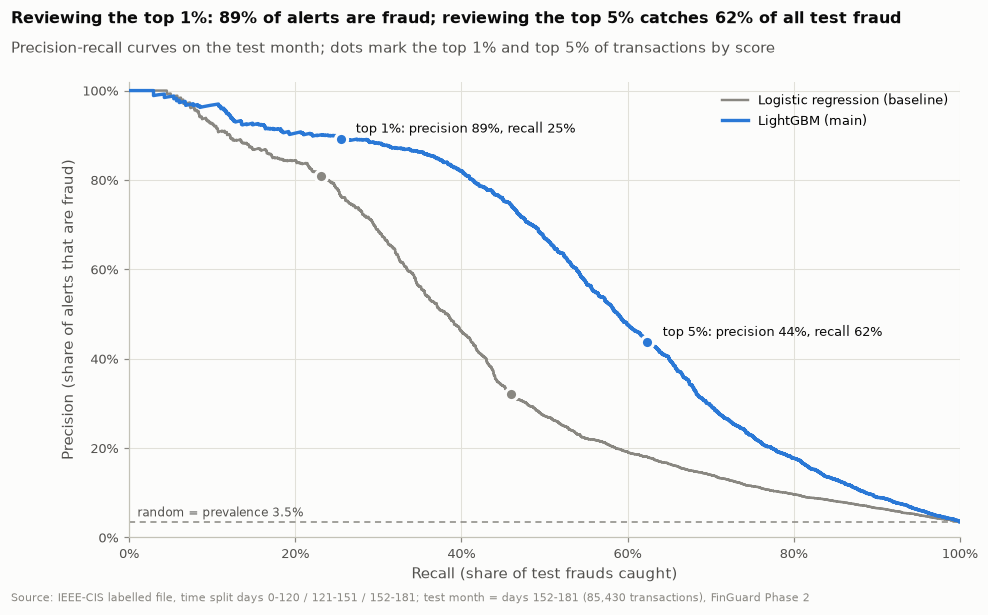

In [6]:
fig = F.fig18_pr_curves(y_te, {"Logistic regression (baseline)": lr["test_raw"], "LightGBM (main)": main["test_raw"]},
                        main="LightGBM (main)")

## 3. Calibration (isotonic, fitted on the validation month)
The raw LightGBM probability is the sigmoid of its score. Isotonic regression maps
validation scores to observed validation fraud rates; it is monotone, so rankings do not change.

In [7]:
iso = C.fit_isotonic(main["valid_raw"], y_va)
p_raw = 1 / (1 + np.exp(-main["test_raw"]))
p_cal = iso.predict(main["test_raw"])
iso_lr = C.fit_isotonic(lr["valid_raw"], y_va)
cal = pd.DataFrame({"LightGBM, uncalibrated": M.calibration(y_te, p_raw),
                    "LightGBM, isotonic": M.calibration(y_te, p_cal),
                    "Logistic regression, isotonic": M.calibration(y_te, iso_lr.predict(lr["test_raw"]))}).T
cal

,brier,ece,mean_predicted,observed_rate,brier_constant_rate
"LightGBM, uncalibrated",0.022132,0.017776,0.017270,0.035046,0.033818
"LightGBM, isotonic",0.020823,0.004086,0.036391,0.035046,0.033818
"Logistic regression, isotonic",0.026044,0.008021,0.041919,0.035046,0.033818


,bin,n,frauds,mean_predicted,observed_rate,lo,hi
14,14,4271,57,0.0146,0.0133,0.0103,0.0173
15,15,4272,95,0.0196,0.0222,0.0182,0.0271
16,16,4271,118,0.0243,0.0276,0.0231,0.0330
17,17,4272,180,0.0427,0.0421,0.0365,0.0486
18,18,4271,325,0.0808,0.0761,0.0685,0.0844
19,19,4272,1865,0.4862,0.4366,0.4218,0.4515


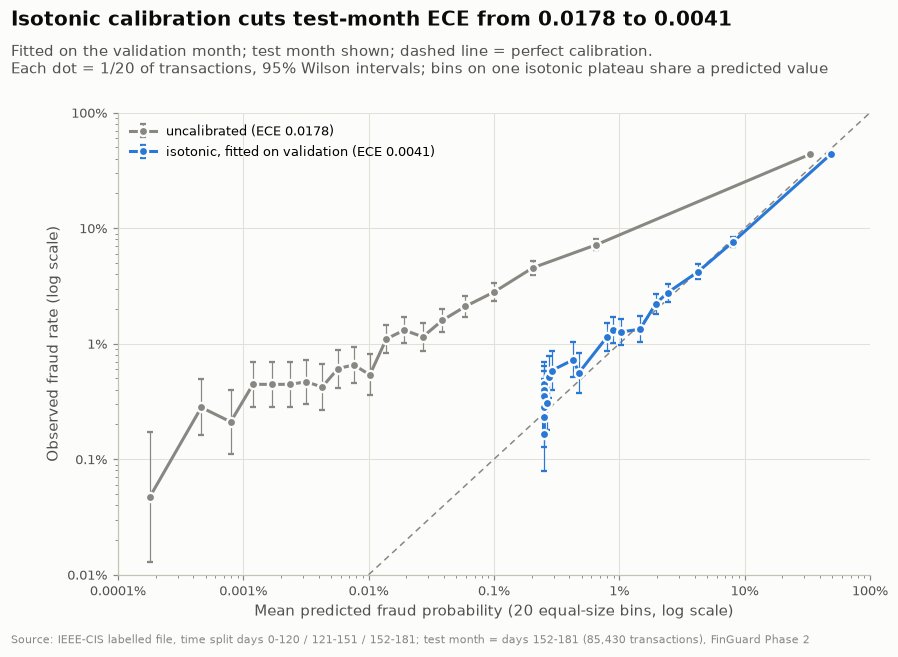

In [8]:
rel_raw, rel_cal = M.reliability(y_te, p_raw, 20), M.reliability(y_te, p_cal, 20)
fig = F.fig19_reliability(rel_raw, rel_cal, M.ece(y_te, p_raw), M.ece(y_te, p_cal))
rel_cal.round(4).tail(6)

## 4. Risk bands
Thresholds are the 99th and 95th percentiles of **validation** scores, frozen, then applied
to the test month. If scores drift, test traffic in each band moves away from 1% / 4%.

In [9]:
bands = C.fit_bands(main["valid_raw"])
p_cal_va = iso.predict(main["valid_raw"])
bt_va = C.band_table(y_va, main["valid_raw"], bands, p_cal_va)
bt_te = C.band_table(y_te, main["test_raw"], bands, p_cal)
print(f"raw-score thresholds: High >= {bands.high:.3f}, Medium >= {bands.medium:.3f}")
print(f"calibrated probability at the thresholds: High >= {iso.predict([bands.high])[0]:.3f}, Medium >= {iso.predict([bands.medium])[0]:.3f}")
bt_te

raw-score thresholds: High >= 2.500, Medium >= -4.527
calibrated probability at the thresholds: High >= 0.871, Medium >= 0.110


,band,n,frauds,mean_calibrated_p,share_of_rows,fraud_rate,lo,hi,share_of_frauds,planned_share
0,High,794,715,0.938921,0.009294,0.900504,0.877716,0.919435,0.238811,0.01
1,Medium,4003,1227,0.349784,0.046857,0.306520,0.292429,0.320983,0.409820,0.04
2,Low,80633,1052,0.011945,0.943849,0.013047,0.012286,0.013854,0.351369,0.95


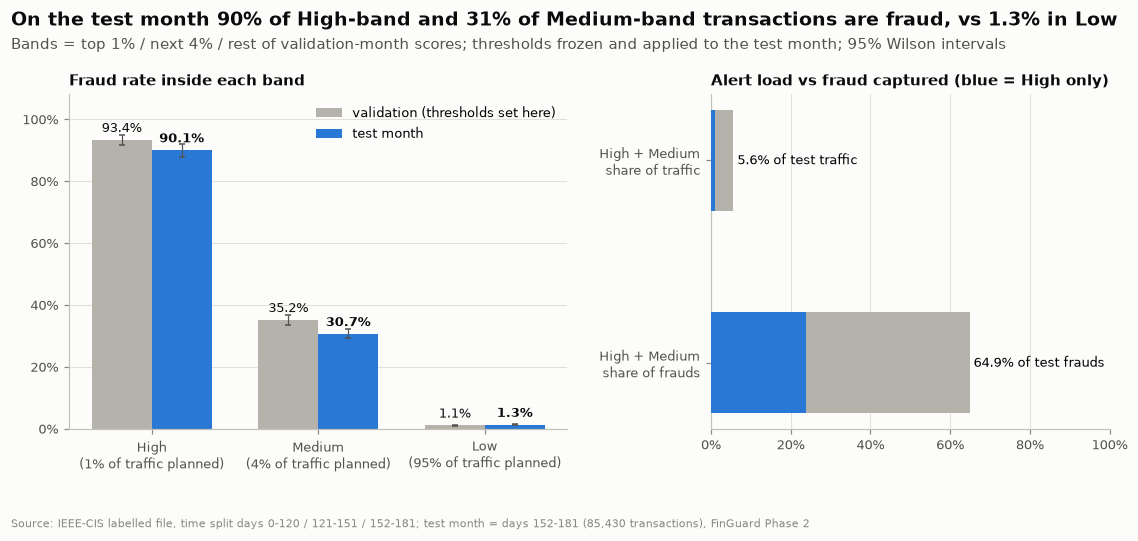

In [10]:
fig = F.fig20_bands(bt_va, bt_te)

## Save results

In [11]:
out = {"selection": sel, "test_metrics": res.to_dict("index"), "bootstrap_ci95": ci, "block_bootstrap_ci95_lightgbm": ci_block,
       "paired_lightgbm_minus_lr": paired, "calibration": cal.to_dict("index"),
       "bands": {"thresholds_raw": {"high": bands.high, "medium": bands.medium},
                 "thresholds_calibrated": {"high": float(iso.predict([bands.high])[0]), "medium": float(iso.predict([bands.medium])[0])},
                 "valid": bt_va.to_dict("records"), "test": bt_te.to_dict("records")}}
(T / "phase2_results.json").write_text(json.dumps(out, indent=1, default=float))
pd.concat([bt_va.assign(period="validation"), bt_te.assign(period="test")]).to_csv(T / "phase2_bands.csv", index=False)
rel_cal.assign(kind="isotonic").pipe(lambda d: pd.concat([d, rel_raw.assign(kind="uncalibrated")])).to_csv(T / "phase2_reliability.csv", index=False)
res.to_csv(T / "phase2_test_metrics.csv")
print("saved phase2_results.json, phase2_bands.csv, phase2_reliability.csv, phase2_test_metrics.csv")

saved phase2_results.json, phase2_bands.csv, phase2_reliability.csv, phase2_test_metrics.csv


### Model bundle for Phase 3
Everything needed to score a new transaction the same way: the fitted feature builder,
the LightGBM model file, the isotonic calibrator and the frozen band thresholds.

In [12]:
import pickle
bundle = {"builder": fs.builder, "model_file": f"artifacts/phase2/lgbm_{codes}/model.txt",
          "columns": json.loads((phase2.ART / f"lgbm_{codes}" / "columns.json").read_text()),
          "isotonic": iso, "bands": bands, "codes_as": codes,
          "note": "proxy entity = card1 + addr1 + first-seen day; heuristic grouping, not a customer"}
with open(phase2.ART / "model_bundle.pkl", "wb") as f:
    pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)
print("saved artifacts/phase2/model_bundle.pkl")

saved artifacts/phase2/model_bundle.pkl
